# Precipitation Intensity Index (SDII) and Extremes in Western Kansas (PERSIANN-CDR)

This notebook computes the **Simple Daily Intensity Index (SDII)** and related ETCCDI-style precipitation
indices from daily **PERSIANN-CDR** precipitation (`NOAA/PERSIANN-CDR`, 0.25°) in Google Earth Engine:

| Index | Definition |
|---|---|
| **SDII** | Total precipitation on wet days ÷ number of wet days (mm/day) |
| **Wet days (R1mm)** | Days with precipitation ≥ 1 mm |
| **PRCPTOT** | Annual total precipitation on wet days (mm) |
| **R10mm / R20mm** | Days with precipitation ≥ 10 mm / ≥ 20 mm |
| **Rx1day** | Maximum 1-day precipitation (mm) |

SDII separates *how often* it rains from *how hard* it rains: a year can be wet because of many rain days
or because of fewer, heavier events.

**Outputs:** annual index table, trend statistics (Theil–Sen, Mann–Kendall), decadal means, time-series figures
and SDII maps for selected years, the long-term mean and the change between early and recent decades.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

In [1]:
import ee

ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username here")

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.7) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

FIG_DIR, OUT_DIR = "figures/precip", "outputs/precip"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

## 2. Parameters

In [3]:
# --- Region of interest: Western Kansas ---
WEST_OF_LON = -99.0   # Kansas spans ~-102.05 to -94.59; use -100.0 for west of the 100th meridian

kansas = (ee.FeatureCollection("TIGER/2018/States")
            .filter(ee.Filter.eq("NAME", "Kansas"))
            .geometry())
west_box = ee.Geometry.Rectangle([-103.0, 36.0, WEST_OF_LON, 41.0])
roi = kansas.intersection(west_box, ee.ErrorMargin(100))

ROI_NAME   = "Western Kansas"
START_YEAR = 1983          # PERSIANN-CDR starts in 1983
END_YEAR   = 2023
WET_THR    = 1.0           # wet-day threshold (mm/day)
MAP_YEARS  = [2010, 2015, 2023]   # years mapped individually (as in the original script)
EARLY, LATE = (1983, 1992), (2014, 2023)   # periods compared in the change map
SCALE      = 27830         # native resolution (m), 0.25°
CRS_TRANSFORM = [0.25, 0, -180, 0, -0.25, 60]

INDICES = ["sdii", "wet_days", "prcptot", "r10mm", "r20mm", "rx1day"]
LABELS = {"sdii": "SDII (mm/day)", "wet_days": "Wet days (≥1 mm)", "prcptot": "PRCPTOT (mm)",
          "r10mm": "R10mm (days)", "r20mm": "R20mm (days)", "rx1day": "Rx1day (mm)"}

## 3. Annual indices in Earth Engine

The `annual_indices` function generalizes the original `pr_intensity()` function: it takes the wet-day
threshold as a parameter (in the original, `thr` was accepted but the value 1 was hard-coded) and
returns all indices for one year as bands of a single image.

In [4]:
pr = (ee.ImageCollection("NOAA/PERSIANN-CDR")
        .select("precipitation")
        .map(lambda im: im.updateMask(im.gte(0))))   # drop fill / negative values

def annual_indices(year, thr=WET_THR):
    y = ee.Number(year).int()
    d0 = ee.Date.fromYMD(y, 1, 1)
    days = pr.filterDate(d0, d0.advance(1, "year"))
    wet_days = days.map(lambda im: im.gte(thr)).sum().rename("wet_days")
    prcptot  = days.map(lambda im: im.updateMask(im.gte(thr))).sum().unmask(0).rename("prcptot")
    sdii     = prcptot.divide(wet_days).rename("sdii")
    r10      = days.map(lambda im: im.gte(10)).sum().rename("r10mm")
    r20      = days.map(lambda im: im.gte(20)).sum().rename("r20mm")
    rx1day   = days.max().rename("rx1day")
    return (ee.Image.cat(sdii, wet_days, prcptot, r10, r20, rx1day)
              .set({"year": y, "n_days": days.size()}))

annual_ic = ee.ImageCollection(ee.List.sequence(START_YEAR, END_YEAR).map(lambda y: annual_indices(y)))

In [5]:
def regional_mean(img):
    vals = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=roi, scale=SCALE, maxPixels=1e9)
    return ee.Feature(None, vals).set({"year": img.get("year"), "n_days": img.get("n_days")})

rows = [f["properties"] for f in annual_ic.map(regional_mean).getInfo()["features"]]
df = (pd.DataFrame(rows).astype({"year": int}).set_index("year").sort_index())
df = df[df["n_days"] >= 360][INDICES]          # complete years only
df.round(2).to_csv(f"{OUT_DIR}/sdii_annual_indices.csv")
print(f"Years: {df.index.min()}–{df.index.max()} ({len(df)})")
df.round(2).tail()

Years: 1983–2023 (41)


,sdii,wet_days,prcptot,r10mm,r20mm,rx1day
year,,,,,,
2019,4.97,135.04,673.80,16.12,4.03,35.65
2020,4.57,119.71,548.17,12.00,2.84,26.63
2021,5.06,111.41,565.03,15.65,2.80,26.37
2022,4.11,105.01,431.75,8.00,1.25,22.99
2023,5.29,129.36,683.82,17.71,4.50,32.84


## 4. Summary and trend statistics

In [6]:
years = df.index.values

def trend(y):
    y = np.asarray(y, dtype=float)
    ok = np.isfinite(y)                       # ignore missing years, if any
    slope, intercept, lo, hi = stats.theilslopes(y[ok], years[ok])
    tau, p = stats.kendalltau(years[ok], y[ok])
    return slope, intercept, lo, hi, tau, p

stats_rows = []
for col in INDICES:
    y = df[col].values
    slope, _, lo, hi, tau, p = trend(y)
    stats_rows.append({"Index": LABELS[col], "Mean": np.nanmean(y), "Std. dev.": np.nanstd(y, ddof=1),
                 "Min (year)": f"{np.nanmin(y):.1f} ({years[np.nanargmin(y)]})",
                 "Max (year)": f"{np.nanmax(y):.1f} ({years[np.nanargmax(y)]})",
                 "Theil–Sen /decade": 10 * slope, "95% CI /decade": f"[{10*lo:.2f}, {10*hi:.2f}]",
                 "MK tau": tau, "MK p-value": p})
trends = pd.DataFrame(stats_rows).set_index("Index")
trends.to_csv(f"{OUT_DIR}/sdii_trend_summary.csv")
trends.round(3)

,Mean,Std. dev.,Min (year),Max (year),Theil–Sen /decade,95% CI /decade,MK tau,MK p-value
Index,,,,,,,,
SDII (mm/day),5.156,0.598,3.8 (2012),6.9 (1996),-0.004,"[-0.19, 0.14]",-0.002,0.982
Wet days (≥1 mm),114.830,14.416,65.0 (1989),139.0 (1993),0.530,"[-3.61, 4.06]",0.027,0.805
PRCPTOT (mm),594.784,106.822,318.3 (2012),769.1 (1993),8.248,"[-24.10, 36.86]",0.071,0.515
R10mm (days),15.227,3.910,5.5 (2012),22.2 (1996),0.380,"[-0.72, 1.46]",0.076,0.486
R20mm (days),3.245,1.636,0.2 (2012),7.8 (2008),0.034,"[-0.40, 0.49]",0.022,0.840
Rx1day (mm),31.837,6.883,17.5 (2012),47.9 (1997),-0.735,"[-2.74, 1.14]",-0.080,0.459


In [7]:
decadal = df.groupby((df.index // 10) * 10)[INDICES].mean().rename(columns=LABELS)
decadal.index = [f"{d}s" for d in decadal.index]
decadal.round(2).to_csv(f"{OUT_DIR}/sdii_decadal_means.csv")
decadal.round(2)

,SDII (mm/day),Wet days (≥1 mm),PRCPTOT (mm),R10mm (days),R20mm (days),Rx1day (mm)
1980s,5.03,112.05,559.88,13.79,2.96,31.65
1990s,5.43,116.09,631.66,16.36,3.81,35.98
2000s,5.26,112.45,595.65,15.70,3.29,30.99
2010s,5.02,117.28,596.51,15.38,2.99,30.53
2020s,4.76,116.37,557.19,13.34,2.85,27.21


## 5. Figures

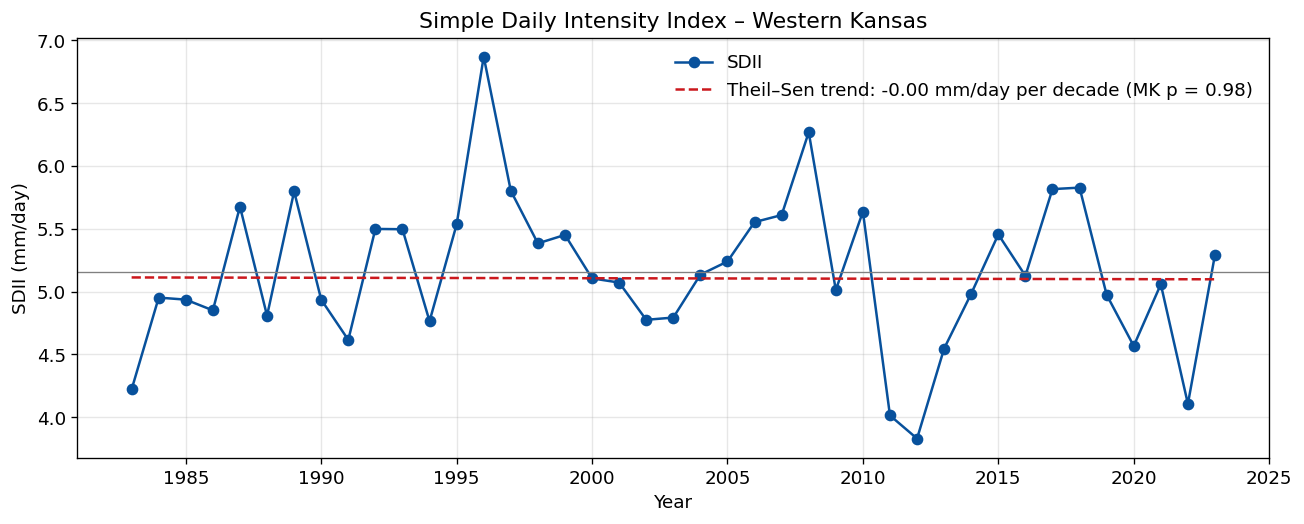

In [8]:
slope, intercept, *_ , p = trend(df["sdii"].values)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(years, df["sdii"], "o-", color="#08519c", label="SDII")
ax.plot(years, intercept + slope * years, "--", color="#cb181d",
        label=f"Theil–Sen trend: {10*slope:+.2f} mm/day per decade (MK p = {p:.2f})")
ax.axhline(df["sdii"].mean(), color="gray", lw=0.8)
ax.set(xlabel="Year", ylabel="SDII (mm/day)", title=f"Simple Daily Intensity Index – {ROI_NAME}")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_sdii_timeseries.png"); plt.show()

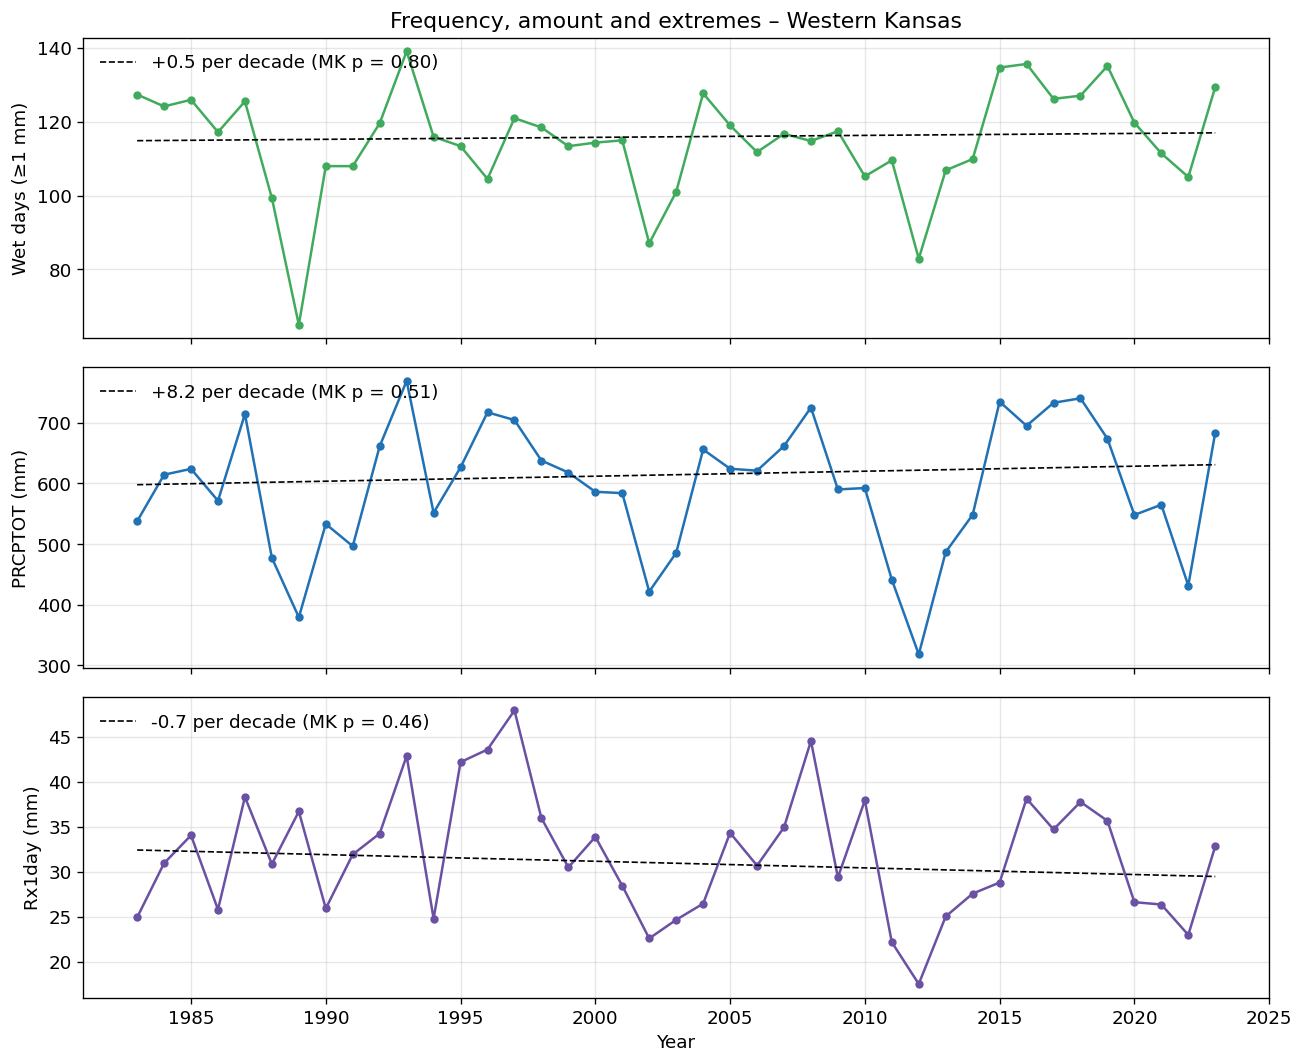

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, col, color in zip(axes, ["wet_days", "prcptot", "rx1day"], ["#41ab5d", "#2171b5", "#6a51a3"]):
    slope, intercept, *_, p = trend(df[col].values)
    ax.plot(years, df[col], "o-", color=color, ms=4)
    ax.plot(years, intercept + slope * years, "k--", lw=1,
            label=f"{10*slope:+.1f} per decade (MK p = {p:.2f})")
    ax.set_ylabel(LABELS[col]); ax.legend(frameon=False, loc="upper left"); ax.grid(alpha=0.3)
axes[0].set_title(f"Frequency, amount and extremes – {ROI_NAME}")
axes[-1].set_xlabel("Year")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_wetdays_prcptot_rx1day.png"); plt.show()

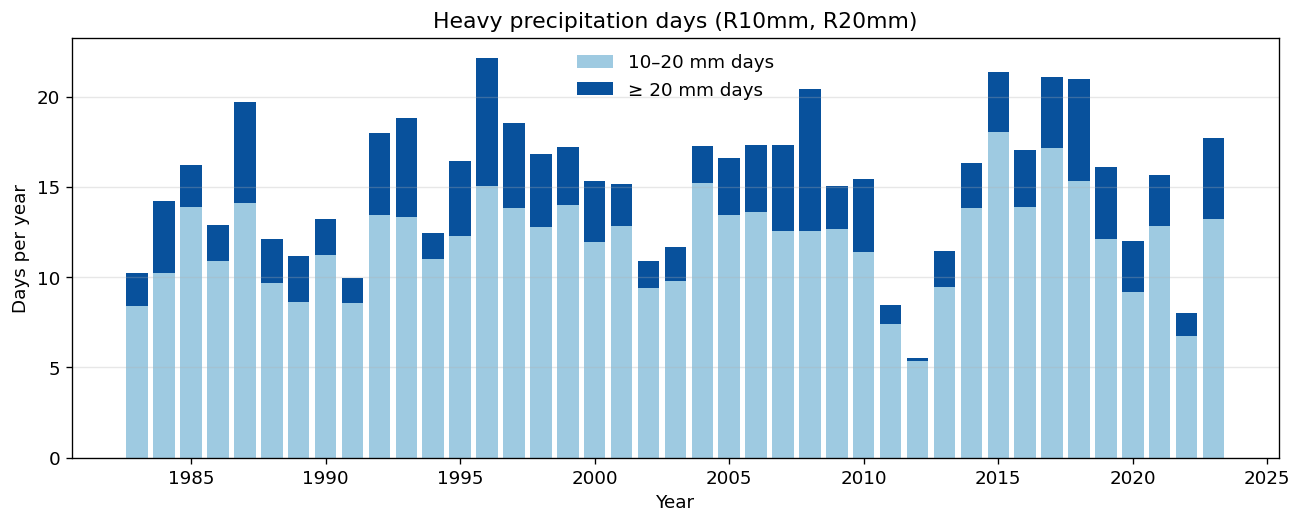

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(years, df["r10mm"] - df["r20mm"], color="#9ecae1", label="10–20 mm days")
ax.bar(years, df["r20mm"], bottom=df["r10mm"] - df["r20mm"], color="#08519c", label="≥ 20 mm days")
ax.set(xlabel="Year", ylabel="Days per year", title="Heavy precipitation days (R10mm, R20mm)")
ax.legend(frameon=False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_heavy_precip_days.png"); plt.show()

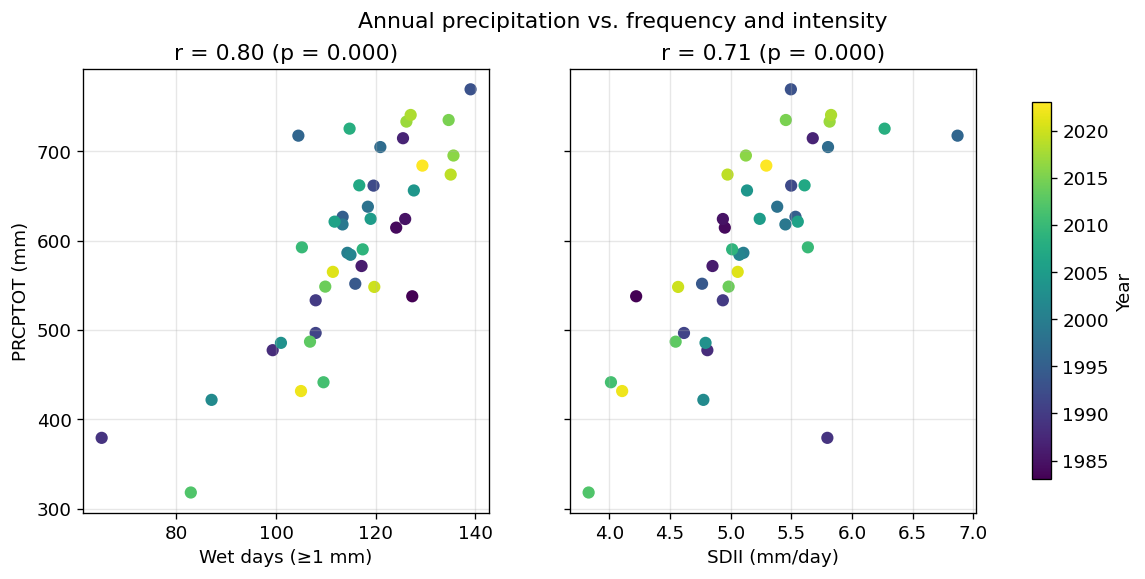

In [11]:
# Are wet years driven by more rain days or by heavier rain?
r_days, p_days = stats.pearsonr(df["wet_days"], df["prcptot"])
r_int,  p_int  = stats.pearsonr(df["sdii"], df["prcptot"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, col, r, p in [(ax1, "wet_days", r_days, p_days), (ax2, "sdii", r_int, p_int)]:
    sc = ax.scatter(df[col], df["prcptot"], c=years, cmap="viridis", s=40)
    ax.set(xlabel=LABELS[col], title=f"r = {r:.2f} (p = {p:.3f})"); ax.grid(alpha=0.3)
ax1.set_ylabel(LABELS["prcptot"])
fig.colorbar(sc, ax=[ax1, ax2], label="Year", shrink=0.85)
fig.suptitle("Annual precipitation vs. frequency and intensity")
fig.savefig(f"{FIG_DIR}/04_frequency_vs_intensity.png", bbox_inches="tight"); plt.show()

## 6. SDII maps

The 0.25° grid is downloaded as arrays (`sampleRectangle`) so the maps have real colour scales.
The study area is outlined in black, Kansas in gray.

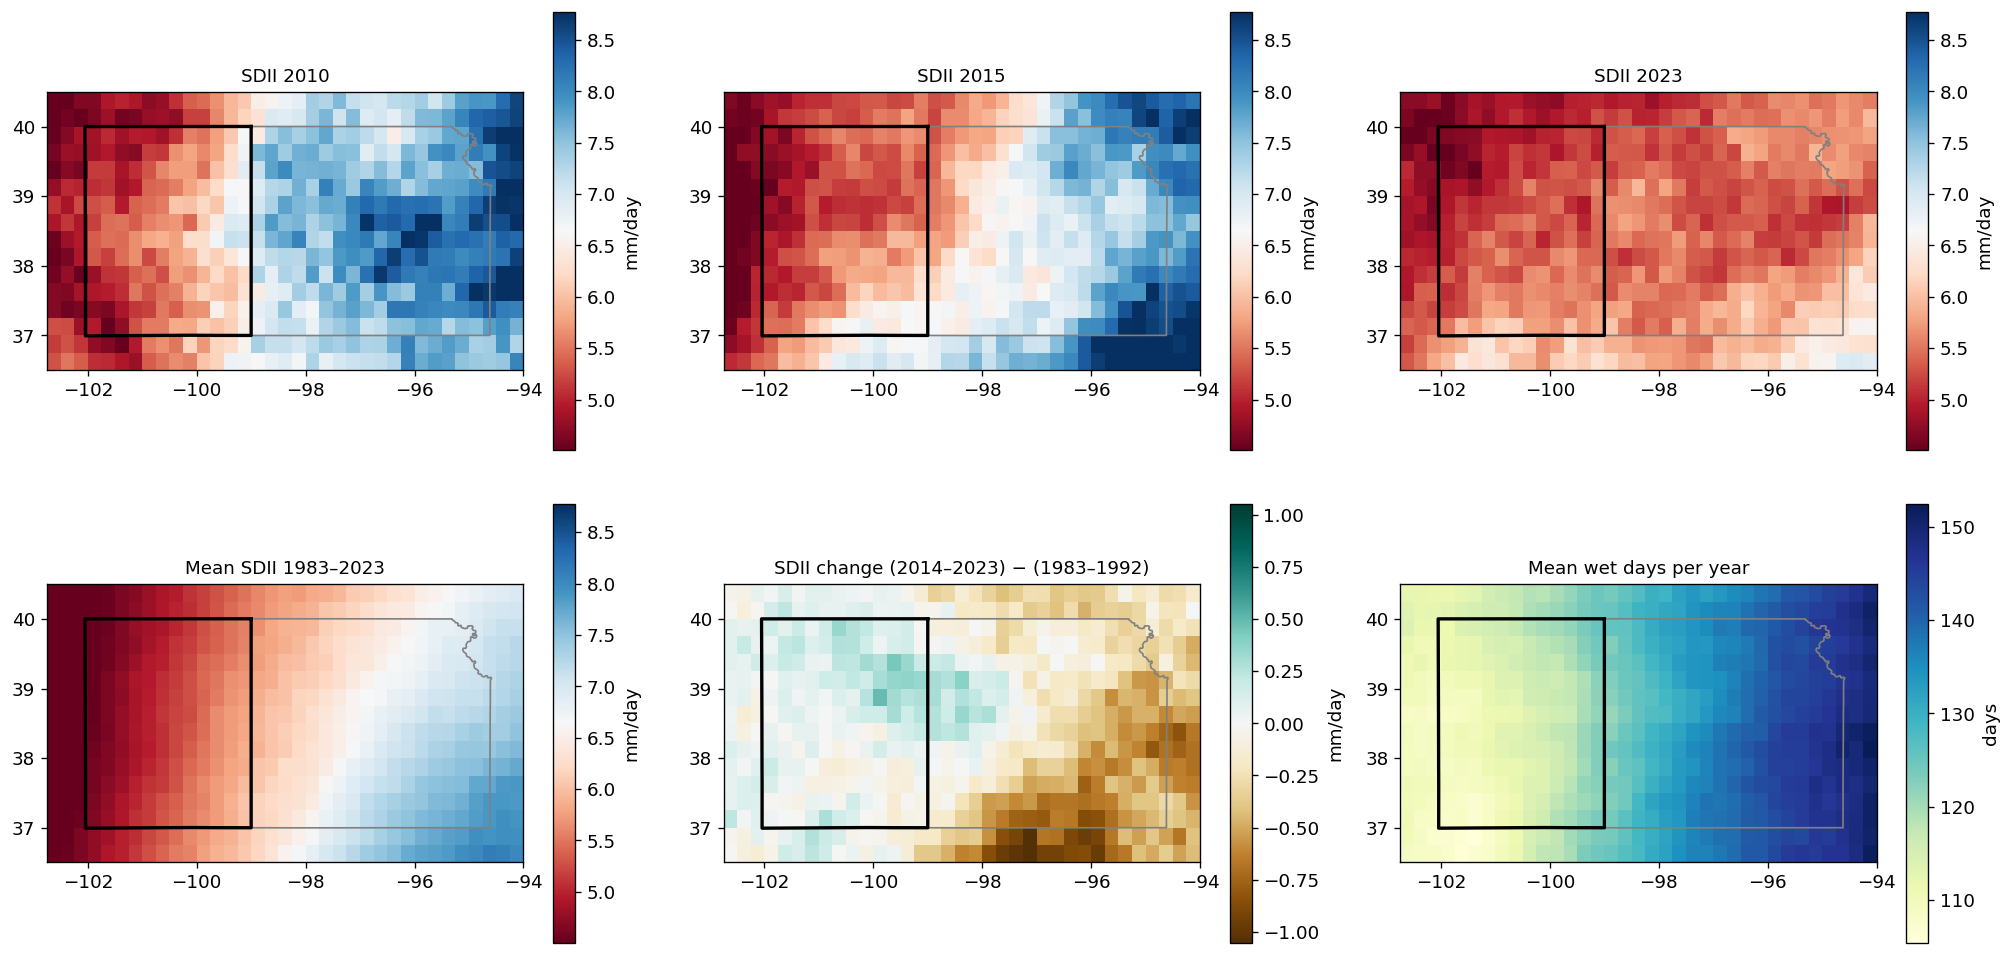

In [12]:
def sdii_of(year):
    return annual_ic.filter(ee.Filter.eq("year", year)).first().select("sdii")

def period_mean(band, y0, y1):
    return annual_ic.filter(ee.Filter.rangeContains("year", y0, y1)).select(band).mean()

bands = [sdii_of(y).rename(f"sdii_{y}") for y in MAP_YEARS] + [
    period_mean("sdii", START_YEAR, END_YEAR).rename("sdii_mean"),
    period_mean("sdii", *LATE).subtract(period_mean("sdii", *EARLY)).rename("sdii_change"),
    period_mean("wet_days", START_YEAR, END_YEAR).rename("wet_days_mean"),
    ee.Image.pixelLonLat(),
]
stack = ee.Image.cat(bands).reproject(crs="EPSG:4326", crsTransform=CRS_TRANSFORM)

view = kansas.bounds().buffer(40000).bounds()
grid = stack.sampleRectangle(region=view, defaultValue=-9999).getInfo()["properties"]
lon, lat = np.array(grid["longitude"]), np.array(grid["latitude"])
arr = lambda name: np.ma.masked_equal(np.array(grid[name], dtype=float), -9999)

def draw_outline(ax, g, **kw):
    if g["type"] == "Polygon":
        ring = np.array(g["coordinates"][0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "MultiPolygon":
        for poly in g["coordinates"]:
            ring = np.array(poly[0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "GeometryCollection":
        for sub in g["geometries"]:
            draw_outline(ax, sub, **kw)

ks_geom, roi_geom = kansas.getInfo(), roi.getInfo()
year_vals = np.concatenate([arr(f"sdii_{y}").compressed() for y in MAP_YEARS])
vmin, vmax = np.percentile(year_vals, [2, 98])
chg = arr("sdii_change"); clim = np.abs(chg).max()

panels = [(arr(f"sdii_{y}"), "RdBu", vmin, vmax, f"SDII {y}", "mm/day") for y in MAP_YEARS] + [
    (arr("sdii_mean"), "RdBu", vmin, vmax, f"Mean SDII {START_YEAR}–{END_YEAR}", "mm/day"),
    (chg, "BrBG", -clim, clim, f"SDII change ({LATE[0]}–{LATE[1]}) − ({EARLY[0]}–{EARLY[1]})", "mm/day"),
    (arr("wet_days_mean"), "YlGnBu", None, None, "Mean wet days per year", "days"),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (data, cmap, lo, hi, title, unit) in zip(axes.flat, panels):
    pm = ax.pcolormesh(lon, lat, data, cmap=cmap, vmin=lo, vmax=hi, shading="nearest")
    draw_outline(ax, ks_geom, color="gray", lw=1)
    draw_outline(ax, roi_geom, color="black", lw=2)
    fig.colorbar(pm, ax=ax, label=unit, shrink=0.8)
    ax.set_title(title, fontsize=11)
    ax.set_aspect(1 / np.cos(np.deg2rad(38.5)))
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/05_sdii_maps.png"); plt.show()

## 7. Notes

- **Data:** Ashouri et al. (2015), *PERSIANN-CDR: Daily precipitation climate data record from multi-satellite observations*,
  BAMS, doi:10.1175/BAMS-D-13-00068.1; NOAA CDR Program, doi:10.7289/V51V5BWQ.
- Index definitions follow the ETCCDI climate change indices (Karl et al. 1999; Zhang et al. 2011).
- Regional values are spatial means of per-pixel indices over the study area at 0.25°.
- Satellite products tend to overestimate light-rain frequency and underestimate extremes compared with rain gauges,
  so absolute values of wet days and Rx1day should be read with care; trends and relative patterns are more robust.
- If an Earth Engine request times out, shorten the period (`START_YEAR`) and run again.